# Xs and Os: what the data can and can't see

*Part of the [Market + Résumé Power Ratings](methodology.html) project. Code and data: [github.com/mastayb/nfl-power-rankings](https://github.com/mastayb/nfl-power-rankings) · [this page as a notebook, with code](https://github.com/mastayb/nfl-power-rankings/blob/main/docs/xs-and-os.ipynb)*

**Short version.** Teams' *tendencies* are very stable from game to game: personnel, coverage mix, man rate, blitz rate, run direction. Their *success in specific situations* mostly isn't. Once you account for how good a team or player is overall, claims like these don't hold up from one part of a season to the next:
* "this team is great against base defense";
* "this QB shreds the blitz";
* "this back is an outside runner".

What does hold up:
* **Overall quality.** Good offenses and good quarterbacks are good against everything.
* **How often a QB gets pressured.** It follows the quarterback, not the offensive line: it carries over when he changes teams, and mostly resets when a team changes quarterbacks.
* **Who gets the ball against man coverage.** Some receivers reliably draw a bigger share of targets against man. They don't gain more per target, though.

**One result we nearly published didn't survive.** Quarterbacks *appeared* to have a durable skill against one-high vs two-high safety looks. It turned out to be an artifact of the data changing source in 2023 (section 4).

In [1]:
import sys, numpy as np, pandas as pd, matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))
pd.set_option("display.precision", 2)
SURF, INK, INK2, MUT, GRID = "#FAFAF7", "#1B1B1F", "#55575E", "#8A8C93", "#E4E4DF"
SKILL, TEND, NULL = "#1F5FBF", "#C2581B", "#8A8F96"
plt.rcParams.update({"font.family": "Noto Sans", "text.color": INK, "axes.edgecolor": GRID,
                     "xtick.color": MUT, "ytick.color": MUT, "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.unicode_minus": False})
A = pd.read_parquet(ROOT / "data" / "persistence_audit.parquet").set_index("measure")

## Data and method

* **Data:** every regular-season run and pass play, 2016–2025 (about 330,000 plays), from [nflverse](https://github.com/nflverse).
  * Personnel, formation and box count are available every season. Pass rushers, coverage (man vs zone, and the coverage shell) and pressure are used from 2018.
  * Participation data is courtesy of **NFL Next Gen Stats via nflverse** (2016–2022) and **FTN Data via nflverse** (2023 on), used under [CC-BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).
* **Efficiency:** [expected points added](https://www.nflfastr.com/) (EPA) per play, adjusted for situation (down and distance, field position, win probability). A first-and-10 at midfield and a third-and-8 aren't compared directly.
* **The key test is persistence.** If a team or player really is better in some situation, their edge there should show up again in a *different* sample of their games.
  * Every skill measure is relative to the team's or player's *own* overall efficiency, so plain "good offense" doesn't count as situation-specific skill.
  * **Odd vs. even games** of the same team-season or player-season is the main test. Both halves span the season, so wear, injuries and scheme drift cancel.
  * **Season to season** (the same player or team the next year) is the forecasting test.
  * The numbers reported are correlations: 0 = pure noise, 1 = perfectly repeatable.
* **Seasons are compared only with themselves.** Before correlating, each season's league average is subtracted. Without this step, any difference *between seasons* (rule changes, league trends, or a change in how the data was charted) is shared by both halves of every team-season and looks like persistent skill. Section 4 shows how much this matters.
* **Sample sizes:** a team typically has about 100 plays per half-season in a given situation, and a single play's EPA swings by about ±1.5. So small situational edges are invisible at the team level. A null result here means "no edge bigger than about 0.03–0.04 EPA per play", not "no edge at all".

## 1. Tendencies are stable, situational skill mostly isn't

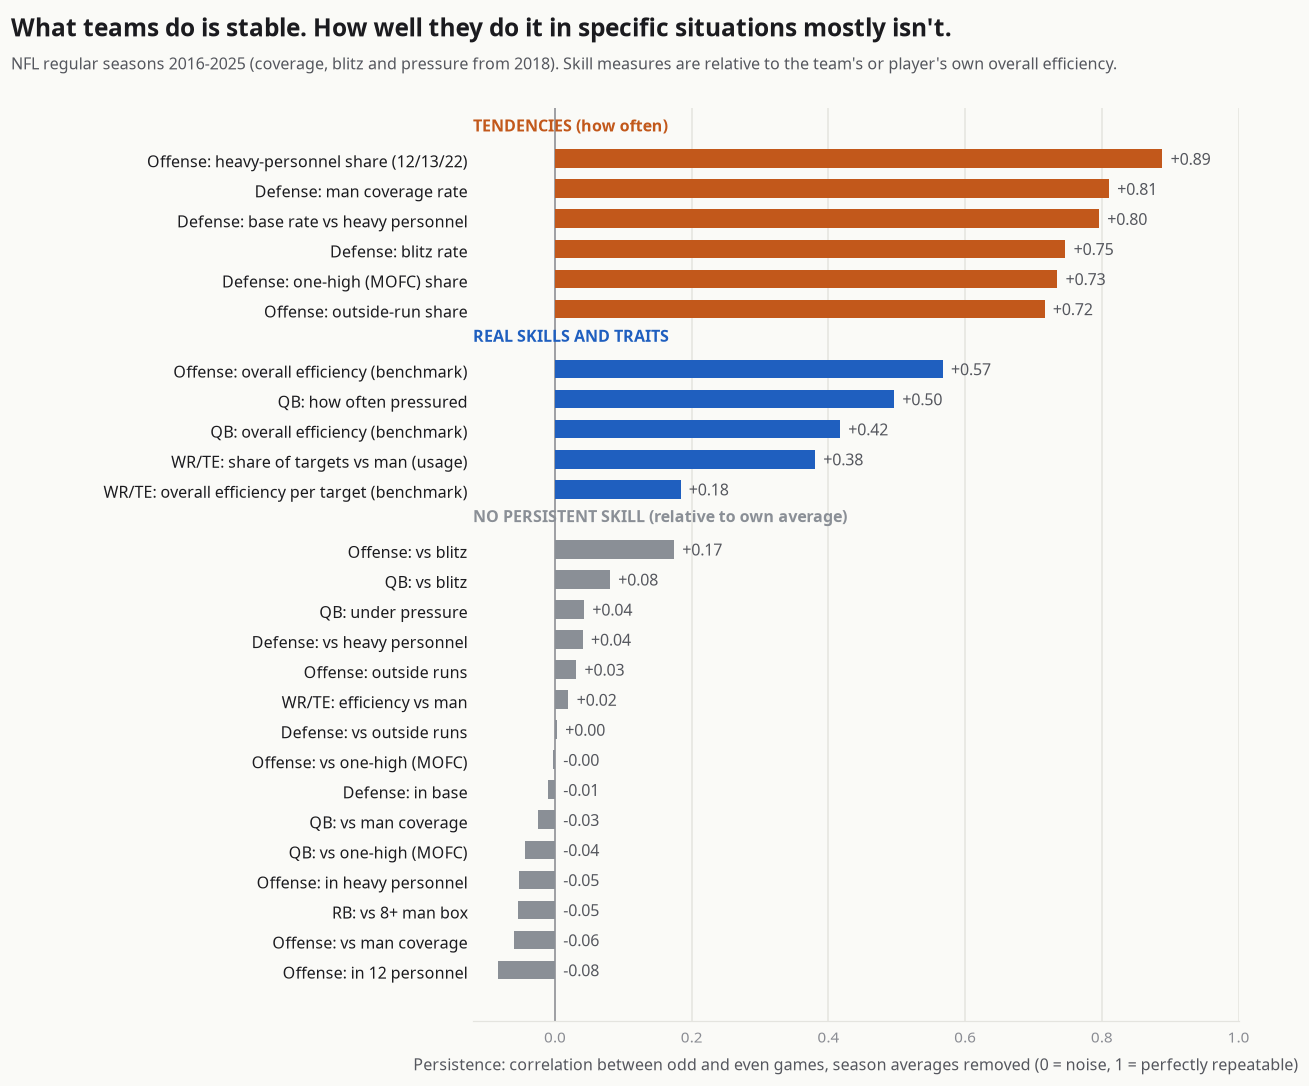

In [2]:
groups = {
    "Tendency": [
        ("Offense: heavy-personnel share (12/13/22)", None), ("Defense: man coverage rate", None),
        ("Defense: base rate vs heavy personnel", None), ("Defense: blitz rate", None),
        ("Defense: one-high (MOFC) share", None), ("Offense: outside-run share", None)],
    "Real skill or trait": [
        ("Offense: overall efficiency", "Offense: overall efficiency (benchmark)"),
        ("QB: overall efficiency", "QB: overall efficiency (benchmark)"),
        ("QB: pressure rate", "QB: how often pressured"),
        ("WR/TE: share of targets vs man", "WR/TE: share of targets vs man (usage)"),
        ("WR/TE: overall efficiency per target", "WR/TE: overall efficiency per target (benchmark)")],
    "No persistent skill": [
        ("Offense: vs blitz", None), ("QB: vs blitz", None), ("QB: under pressure", None),
        ("Defense: vs heavy personnel", None), ("Offense: outside runs", None),
        ("WR/TE: efficiency vs man", None), ("Defense: vs outside runs", None),
        ("QB: vs man", "QB: vs man coverage"), ("Offense: vs one-high (MOFC)", None),
        ("Defense: in base", None), ("QB: vs one-high (MOFC)", None),
        ("Offense: in heavy personnel", None), ("RB: vs 8+ box", "RB: vs 8+ man box"),
        ("Offense: vs man", "Offense: vs man coverage"), ("Offense: in 12 personnel", None)],
}
rows = [(lab or m, g, A.loc[m, "r_oddeven_demeaned"]) for g, ms in groups.items() for m, lab in ms]
T = pd.DataFrame(rows, columns=["measure", "group", "r"])
order = list(groups)
T["g"] = T.group.map({g: i for i, g in enumerate(order)})
T = T.sort_values(["g", "r"], ascending=[True, False]).reset_index(drop=True)
y = np.arange(len(T))[::-1] + np.repeat([2, 1, 0], T.group.value_counts()[order].to_numpy())
fig, ax = plt.subplots(figsize=(12, 10), dpi=110)
fig.subplots_adjust(left=0.37, right=0.95, top=0.89, bottom=0.06)
col = {"Tendency": TEND, "Real skill or trait": SKILL, "No persistent skill": NULL}
for yi, r in zip(y, T.itertuples()):
    ax.barh(yi, r.r, height=0.62, color=col[r.group], zorder=3)
    ax.text(max(r.r, 0) + 0.012, yi, f"{r.r:+.2f}", va="center", fontsize=10.5, color=INK2)
ax.set_yticks(y, T.measure, fontsize=10.5, color=INK)
ax.set_xlim(-0.12, 1.0); ax.axvline(0, color=MUT, lw=1)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(length=0); ax.grid(axis="x", color=GRID, lw=1); ax.set_axisbelow(True)
ax.set_xlabel("Persistence: correlation between odd and even games, season averages removed (0 = noise, 1 = perfectly repeatable)",
              color=INK2, fontsize=10.5)
heads = {"Tendency": "TENDENCIES (how often)", "Real skill or trait": "REAL SKILLS AND TRAITS",
         "No persistent skill": "NO PERSISTENT SKILL (relative to own average)"}
for g in order:
    ax.text(-0.12, y[T.group == g].max() + 0.75, heads[g], fontsize=10.5, fontweight="bold", color=col[g], va="bottom")
fig.text(0.02, 0.955, "What teams do is stable. How well they do it in specific situations mostly isn't.",
         fontsize=16, fontweight="bold")
fig.text(0.02, 0.925, "NFL regular seasons 2016-2025 (coverage, blitz and pressure from 2018). Skill measures are relative to the team's or player's own overall efficiency.",
         fontsize=10.5, color=INK2)
plt.show()

**How to read it:**
* **Orange (tendencies):** how often a team does something. These persist strongly (0.7–0.9). A defense that leans on man coverage, blitzes a lot or stays in base against 12 personnel keeps doing it.
* **Blue (real skills and traits):**
  * Overall offensive, QB and receiver efficiency are the benchmarks. Teams and players really do differ in how good they are.
  * Beyond that, only two things persist: how often a QB is pressured, and receivers' share of targets against man coverage. Both are about *what happens*, not *how well it goes*.
* **Gray (no persistent skill):** efficiency in a specific situation, relative to the team's or player's own average. These sit near zero. The situations tested:
  * personnel groupings;
  * man coverage and coverage shells;
  * the blitz and pressure;
  * stacked boxes;
  * inside vs outside runs.

  A team that looked great against base defense in its odd games is no more likely to do so in its even games. "Offense vs blitz" (+0.17) is the closest call, but it doesn't carry over from one season to the next (−0.01).

## 2. The blitz and pressure: a skill, or just a good QB?

Charts of "QB EPA against the blitz" are common. The question is whether they show a separate skill, or just which quarterbacks are good.

In [3]:
from player_persistence import load as load_plays
d = load_plays()
part = pd.concat([pd.read_parquet(ROOT / "data" / "cache" / f"participation_{y}.parquet")
                  [["nflverse_game_id", "play_id", "was_pressure"]] for y in range(2018, 2026)])
part = part.assign(play_id=part.play_id.astype(float)).rename(columns={"nflverse_game_id": "game_id"})
d = d.merge(part, on=["game_id", "play_id"], how="left")
q = d[(d.qb_dropback == 1) & d.passer_player_id.notna()]

# 1) raw "EPA vs the blitz" is mostly overall QB quality
b = q[q.blitz.notna()].assign(bl=lambda x: x.adj.where(x.blitz == 1))
bb = b.groupby(["passer_player_id", "season"]).agg(blz=("bl", "mean"), nb=("bl", "count"), all=("adj", "mean"))
bb = bb[bb.nb >= 60].reset_index()
for c in ("blz", "all"):
    bb[c] -= bb.groupby("season")[c].transform("mean")
r_blitz_overall = bb.blz.corr(bb["all"])

# 2) does pressure rate follow the QB or the team? (season to season, season averages removed)
p = q[q.was_pressure.notna()].assign(pr=lambda x: x.was_pressure.astype(float))
g = p.groupby(["passer_player_id", "season"]).agg(pr=("pr", "mean"), n=("pr", "size"),
                                                  team=("posteam", lambda s: s.mode().iloc[0])).reset_index()
g = g[g.n >= 150]
g["pr"] -= g.groupby("season").pr.transform("mean")
j = g.merge(g.assign(season=g.season - 1), on=["passer_player_id", "season"], suffixes=("", "_next"))
t = p.groupby(["posteam", "season"]).pr.mean().rename("tp").reset_index()
t["tp"] -= t.groupby("season").tp.transform("mean")
starter = g.sort_values("n").groupby(["team", "season"]).passer_player_id.last().rename("qb").reset_index()
starter = starter.rename(columns={"team": "posteam"})
tt = (t.merge(t.assign(season=t.season - 1), on=["posteam", "season"], suffixes=("", "_next"))
       .merge(starter, on=["posteam", "season"])
       .merge(starter.assign(season=starter.season - 1), on=["posteam", "season"], suffixes=("", "_next")))
port = pd.DataFrame([
    ("Same QB, same team", j[j.team == j.team_next].pipe(lambda x: (x.pr.corr(x.pr_next), len(x)))),
    ("QB who changed teams", j[j.team != j.team_next].pipe(lambda x: (x.pr.corr(x.pr_next), len(x)))),
    ("Team that changed QBs", tt[tt.qb != tt.qb_next].pipe(lambda x: (x.tp.corr(x.tp_next), len(x)))),
], columns=["comparison", "rn"])
port[["Pressure rate, year to year (r)", "pairs"]] = pd.DataFrame(port.rn.tolist())
print(f"Raw QB EPA vs the blitz correlates {r_blitz_overall:.2f} with the same QB's overall EPA ({len(bb)} QB-seasons).")
port.drop(columns="rn").set_index("comparison")

Raw QB EPA vs the blitz correlates 0.73 with the same QB's overall EPA (275 QB-seasons).


,"Pressure rate, year to year (r)",pairs
comparison,,
"Same QB, same team",0.54,157
QB who changed teams,0.33,39
Team that changed QBs,0.10,93


| Measure (season averages removed) | Odd/even | Season to season |
|---|---|---|
| QB: EPA vs blitz, relative to own | 0.08 | −0.03 |
| Offense: EPA vs blitz, relative to own | 0.17 | −0.01 |
| QB: EPA under pressure, relative to own | 0.04 | 0.04 |
| **QB: how often pressured** | **0.50** | **0.49** |
| QB: how often pressure becomes a sack (2023+ only) | 0.47 | 0.14 |

* **"EPA vs the blitz" is mostly a QB-quality chart.** A QB's raw EPA against the blitz correlates about 0.7 with his overall EPA. Relative to his own level, how he does against the blitz doesn't repeat.
* **Same for pressure.** Every QB is much worse under pressure. How much worse, relative to his own level, is noise.
* **Getting pressured is the real trait, and it belongs to the quarterback.** A QB's pressure rate persists within a season and into the next. It mostly travels with him when he changes teams, and mostly resets when a team changes QBs. It reflects how long he holds the ball and how he handles the pocket, not just his line.
* **Turning pressure into sacks** also looks like a QB trait within a season. It can only be measured from 2023, because the older Next Gen Stats data never marks a sacked play as pressured. With two seasons of pairs, the year-to-year number is too noisy to call.

## 3. Receivers vs man coverage: real, but not predictable before kickoff

* **Usage persists, efficiency doesn't.** Some receivers become the QB's go-to read against man coverage: a receiver's share of targets against man relative to zone persists at **0.38**. Whether he gains *more per target* against man is noise (0.02).
* **The mechanism checks out.** Using the defense's *actual* man rate in a game, man-favoured receivers get more targets about as much as predicted (slope 1.19, 90% interval 0.73–1.76, on about 10,000 receiver-games).
* **But it can't be predicted in advance.** A defense's man rate in its earlier games only moderately predicts its man rate in the next game (r = 0.59): coordinators game-plan for each opponent. Early in a season, a receiver's split also has to be shrunk heavily. So a typical pre-game adjustment is about **0.04 targets**, and 0.1 even for the strongest matchups. That's too small to matter for player projections.

## 4. The finding that wasn't: one-high vs two-high

Coverage shells are grouped by how many deep safeties the defense shows:
* **One-high (middle of the field closed, MOFC):** Cover 1 and Cover 3.
* **Two-high (middle of the field open, MOFO):** Cover 2, 4 and 6, and 2-Man.

Pooled across seasons, quarterbacks and offenses seemed to differ durably in how they did against one-high relative to two-high looks. The correlations were about 0.24 between odd and even games and 0.3 from one season to the next. That would have been the most interesting result on this page.

It doesn't survive comparing each season only with itself:
* The participation data changed source in 2023, from Next Gen Stats to FTN Data, and the two chart coverage differently.
* League-wide, the EPA gap between one-high and two-high looks moved between seasons. Every team-season in a given year shares that offset, in both its odd and its even games.
* That shared offset looked like a persistent skill. Removing season averages takes the correlation to about zero.
* QB performance under pressure had the same problem (0.47 → 0.04). Tendencies, overall quality and receiver usage barely moved.

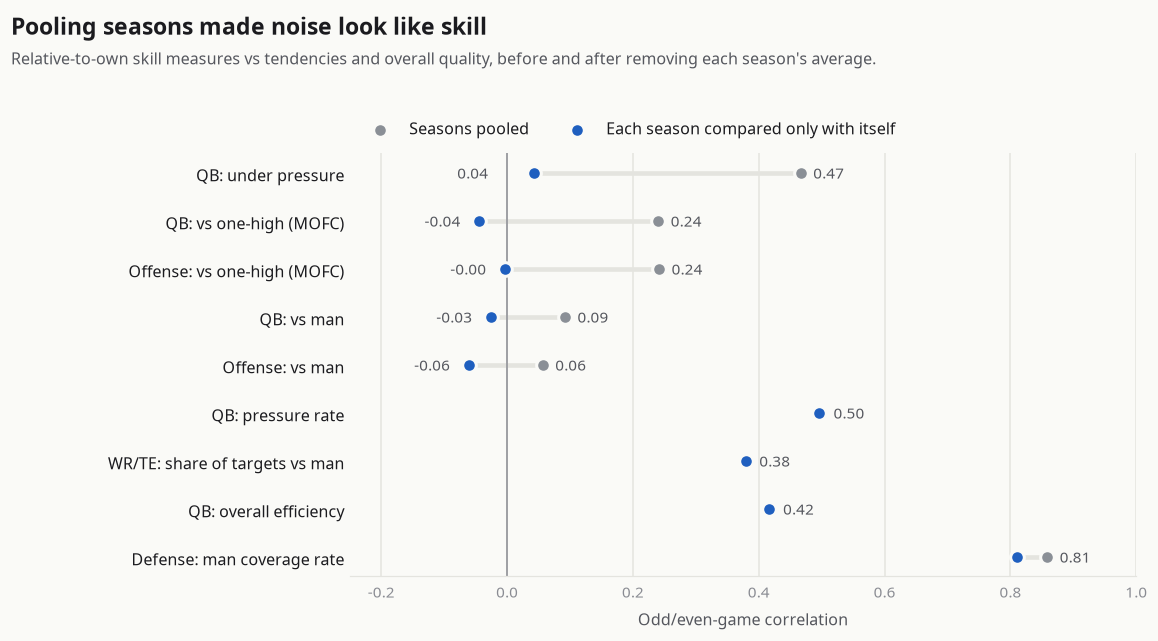

In [4]:
pick = ["QB: under pressure", "QB: vs one-high (MOFC)", "Offense: vs one-high (MOFC)", "QB: vs man", "Offense: vs man",
        "QB: pressure rate", "WR/TE: share of targets vs man", "QB: overall efficiency", "Defense: man coverage rate"]
D = A.loc[pick, ["r_oddeven_raw", "r_oddeven_demeaned"]].iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.0), dpi=110)
fig.subplots_adjust(left=0.30, right=0.95, top=0.76, bottom=0.12)
yy = np.arange(len(D))
ax.hlines(yy, D.r_oddeven_demeaned, D.r_oddeven_raw, color=GRID, lw=3, zorder=1)
ax.scatter(D.r_oddeven_raw, yy, s=80, color=NULL, zorder=3, edgecolor=SURF, linewidth=2, label="Seasons pooled")
ax.scatter(D.r_oddeven_demeaned, yy, s=80, color=SKILL, zorder=4, edgecolor=SURF, linewidth=2,
           label="Each season compared only with itself")
for yi, (a, b) in zip(yy, D.itertuples(index=False)):
    if abs(a - b) > 0.05:
        ax.text(a + 0.02, yi, f"{a:.2f}", va="center", fontsize=10, color=INK2)
        ax.text(min(b, 0) - 0.03, yi, f"{b:.2f}", va="center", ha="right", fontsize=10, color=INK2)
    else:
        ax.text(max(a, b) + 0.02, yi, f"{b:.2f}", va="center", fontsize=10, color=INK2)
ax.set_yticks(yy, D.index, fontsize=10.5, color=INK)
ax.set_xlim(-0.25, 1.0); ax.axvline(0, color=MUT, lw=1)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(length=0); ax.grid(axis="x", color=GRID, lw=1); ax.set_axisbelow(True)
ax.set_xlabel("Odd/even-game correlation", color=INK2, fontsize=10.5)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=10.5)
fig.text(0.02, 0.94, "Pooling seasons made noise look like skill", fontsize=15, fontweight="bold")
fig.text(0.02, 0.895, "Relative-to-own skill measures vs tendencies and overall quality, before and after removing each season's average.",
         fontsize=10.5, color=INK2)
plt.show()

## 5. What didn't hold up

Measured against the team's or player's own average, none of these persisted. With season averages removed, the correlations run from about −0.08 to +0.17, mostly near 0:

* **Personnel matchups:** offenses in 12 or heavy personnel; defenses against heavy personnel or in base. League-wide, passing from heavy sets against base looked better than running from them (+0.04 to +0.10 EPA per play for passes, −0.02 to −0.06 for runs). That's football logic, but it isn't statistically established here.
* **Coverage:** man vs zone, and one-high vs two-high shells, for QBs, offenses and receivers' efficiency.
* **The blitz and pressure:** performance relative to own, for QBs and offenses.
* **Box counts:** running backs against 8+ man boxes.
* **Run direction:** inside vs outside runs, and left vs right, for offenses, backs and defenses.
* **Opponent quality:** "flat-track bullies" who beat up on bad defenses, "giant killers", and unusually steady or volatile teams. The slopes and the game-to-game consistency show no persistence across 640 team-seasons, 2006–2025.

**What betting markets price.** Game lines move about **3 points** when a starting QB is newly out, and 0.2–0.7 points for other starters. That doesn't show up as a mispricing when measured against results.

## 6. Why: football is an adaptive game

The pattern is the same across every test: **stable choices, unstable payoffs.** That's what a competitive, adaptive game looks like:
* If a team had a reliable edge in some situation, opponents would stop giving it that situation, and coordinators adjust within games too. In equilibrium, the *payoffs* of different looks even out even though the *choices* differ a lot. That's the logic of mixed strategies in [game theory](https://en.wikipedia.org/wiki/Nash_equilibrium).
* What can't be adjusted away is plain quality. Good offenses are good against everything.
* The traits that do persist are things a player does to himself: how long a QB holds the ball, and who he looks for against man. They aren't edges an opponent can take away.

**Coaching still matters**, mostly through overall efficiency (scheme, play design, development) and through measurable decisions such as early-down pass rate and fourth-down aggressiveness. What doesn't show up is coaching that creates *repeatable, situation-specific* edges large enough to see in public data.

**What could change these conclusions:**
* **Tracking data:** who covered whom on each play, leverage, and route-vs-coverage pairings. The real matchups happen at that level, and outside the NFL's [Big Data Bowl](https://operations.nfl.com/gameday/analytics/big-data-bowl/) samples it isn't public.
* **Longer windows:** multi-season samples with the same coordinator or QB.
* **League-wide habits:** things the whole league might be getting wrong (for example running too often from heavy sets against base), rather than team-specific edges.

## Reproduce

Scripts in the [repository](https://github.com/mastayb/nfl-power-rankings):
* `scripts/persistence_audit.py`: every persistence number on this page, pooled and with season averages removed.
* `scripts/xo_explore.py`: personnel response and personnel interactions.
* `scripts/xo_round2.py`: market premium and opponent quality.
* `scripts/player_persistence.py`: player and team splits.
* `scripts/run_direction.py`: run direction.
* `scripts/matchup_validation.py`: pre-game matchup scores against outcomes.
* `scripts/injury_premium.py`: the injury values.

Statistical methods (situation-adjusted EPA, split-sample [reliability](https://en.wikipedia.org/wiki/Reliability_%28statistics%29), [shrinkage](https://en.wikipedia.org/wiki/Shrinkage_%28statistics%29), season-cluster [bootstrap](https://en.wikipedia.org/wiki/Bootstrapping_%28statistics%29)) are described on the [methodology page](methodology.html).